# Product Recommendation Model

**Goal:** Predicts which product category between Sports,Electronics,Clothing,Groceries or Books a customer will buy using their social media profile and their transaction.

**Pipeline:** Load,inspect,clean,fix the join key,merge,EDA,features,split,baseline,train,evaluate and save.




## Step 0: Import libraries

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


**Explanation:** `pandas` handles tables, `numpy` handles numbers, and `matplotlib` and `seaborn` draw plots. We import these first because every step after this uses them. The other tools like (`sklearn`) come later, in the step where we first use them, so each import sits next to the code that needs it.

## Step 1: Load the datasets

In [56]:
Socials= pd.read_csv("data/customer_social_profiles - customer_social_profiles.csv")
Trans= pd.read_csv("data/customer_transactions - customer_transactions.csv")

**Explanation:** Here we read each CSV file into a table (a DataFrame) and save it under a name: `Socials` for the social profiles and `Trans` for the transactions. We save them in variables because Python forgets anything it reads unless it is stored, and every later step needs these two tables.

## Step 2: Inspect the data

In [3]:
Socials.head()

,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


In [4]:
Trans.head()

,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


In [5]:
Socials.tail()

,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
150,A125,LinkedIn,66,4.7,Positive
151,A116,Twitter,78,1.1,Negative
152,A189,Twitter,59,3.8,Neutral
153,A162,Twitter,71,4.8,Positive
154,A155,TikTok,98,4.8,Positive


In [6]:
Trans.tail()

,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
145,102,1146,88,2024-05-25,Sports,2.7
146,100,1147,387,2024-05-26,Books,4.6
147,104,1148,409,2024-05-27,Clothing,1.4
148,189,1149,178,2024-05-28,Sports,3.0
149,113,1150,316,2024-05-29,Clothing,1.0


**Explanation:** Since we have loaded both datasets, we now look at the first and last rows with `head()` and `tail()`. This is the fastest way to see which columns exist and how the values are written. It also helps us spot the **join key** (the column that links the two tables) and the **target** (`product_category`, the column we want to predict).

In [7]:
print( "The columns/row count for Socials:",Socials.shape)
print("The columns/rows count for Transaction data:", Trans.shape)

The columns/row count for Socials: (155, 5)
The columns/rows count for Transaction data: (150, 6)


In [8]:
Socials.info()
print("-"*40)
Trans.info()

<class 'pandas.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id_new          155 non-null    str    
 1   social_media_platform    155 non-null    str    
 2   engagement_score         155 non-null    int64  
 3   purchase_interest_score  155 non-null    float64
 4   review_sentiment         155 non-null    str    
dtypes: float64(1), int64(1), str(3)
memory usage: 6.2 KB
----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id_legacy  150 non-null    int64  
 1   transaction_id      150 non-null    int64  
 2   purchase_amount     150 non-null    int64  
 3   purchase_date       150 non-null    str    
 4   product_category    150 non-null    st

In [9]:
Socials.isnull().sum()/Socials.shape[0]*100

customer_id_new            0.0
social_media_platform      0.0
engagement_score           0.0
purchase_interest_score    0.0
review_sentiment           0.0
dtype: float64

In [10]:
Trans.isnull().sum()/Trans.shape[0]*100

customer_id_legacy    0.000000
transaction_id        0.000000
purchase_amount       0.000000
purchase_date         0.000000
product_category      0.000000
customer_rating       6.666667
dtype: float64

In [11]:
print("Duplicates in Socials ",Socials.duplicated().sum())
print("Duplicates in Trans ",Trans.duplicated().sum())

Duplicates in Socials  5
Duplicates in Trans  0


**Explanation:** `shape` gives the size, `info()` gives column types and non-null counts, `isnull()` gives the percentage missing, and `duplicated()` counts repeated rows. We check all of these because we cannot trust data we have not verified.

### What the output already tells us

| Finding | Why it matters |
|---|---|
| `Socials` has 155 rows, `Trans` has 150 | The tables have different sizes, so the merge needs care |
| `Socials` has **5 duplicate rows** | We remove them in Step 3 |
| `customer_rating` is **6.7% missing** (10 rows) | We handle it after the split in Step 9 |
| `purchase_date` is type `object` (text) | We convert it to a date in Step 3 |
| Join key looks like `A178` in `Socials` but `151` in `Trans` | **The formats differ**, so we must fix them in Step 4 |
| `Socials` has 155 rows but only **84 unique** `customer_id_new` values | One customer appears on **several rows**, so a plain merge would multiply rows. We fix this in Step 5 |

### Step 2b: EDA on the raw tables

In [12]:
for i in Socials.select_dtypes(include="object").columns:
    print(Socials[i].value_counts())
    print("-"*40)

customer_id_new
A155    7
A116    5
A189    5
A125    5
A185    4
       ..
A199    1
A139    1
A182    1
A140    1
A132    1
Name: count, Length: 84, dtype: int64
----------------------------------------
social_media_platform
Twitter      38
LinkedIn     32
TikTok       32
Facebook     27
Instagram    26
Name: count, dtype: int64
----------------------------------------
review_sentiment
Positive    63
Neutral     50
Negative    42
Name: count, dtype: int64
----------------------------------------


C:\Users\Elyse\AppData\Local\Temp\ipykernel_25800\1367886235.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for i in Socials.select_dtypes(include="object").columns:


In [13]:
for i in Trans.select_dtypes(include="object").columns:
    print(Trans[i].value_counts())
    print("-"*40)

purchase_date
2024-01-01    1
2024-01-02    1
2024-01-03    1
2024-01-04    1
2024-01-05    1
             ..
2024-05-25    1
2024-05-26    1
2024-05-27    1
2024-05-28    1
2024-05-29    1
Name: count, Length: 150, dtype: int64
----------------------------------------
product_category
Sports         35
Electronics    34
Clothing       28
Groceries      28
Books          25
Name: count, dtype: int64
----------------------------------------


C:\Users\Elyse\AppData\Local\Temp\ipykernel_25800\1351669912.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for i in Trans.select_dtypes(include="object").columns:


In [14]:
Socials.describe().T

,count,mean,std,min,25%,50%,75%,max
engagement_score,155.0,75.606452,14.568021,50.0,63.50,77.0,87.5,99.0
purchase_interest_score,155.0,3.152903,1.142867,1.0,2.35,3.2,4.1,5.0


In [15]:
Trans.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id_legacy,150.0,148.760,30.046425,100.0,121.25,150.5,174.75,199.0
transaction_id,150.0,1075.500,43.445368,1001.0,1038.25,1075.5,1112.75,1150.0
purchase_amount,150.0,280.780,121.329595,51.0,179.00,274.0,388.50,495.0
customer_rating,140.0,2.985,1.206990,1.0,1.95,3.0,4.00,5.0


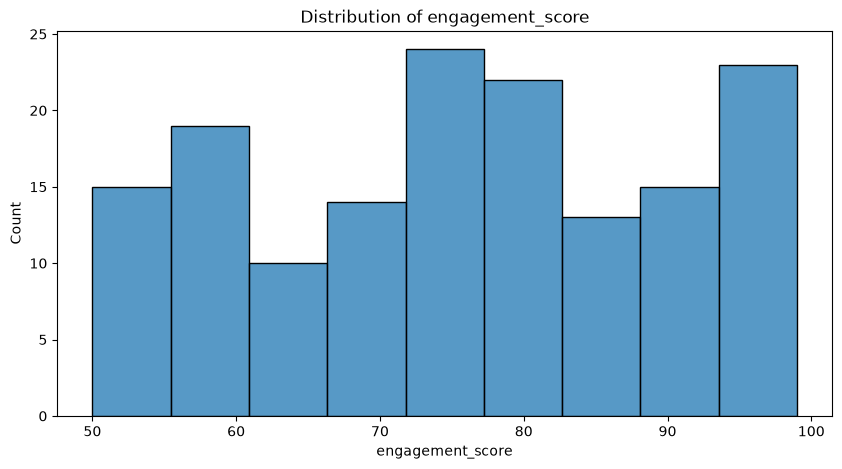

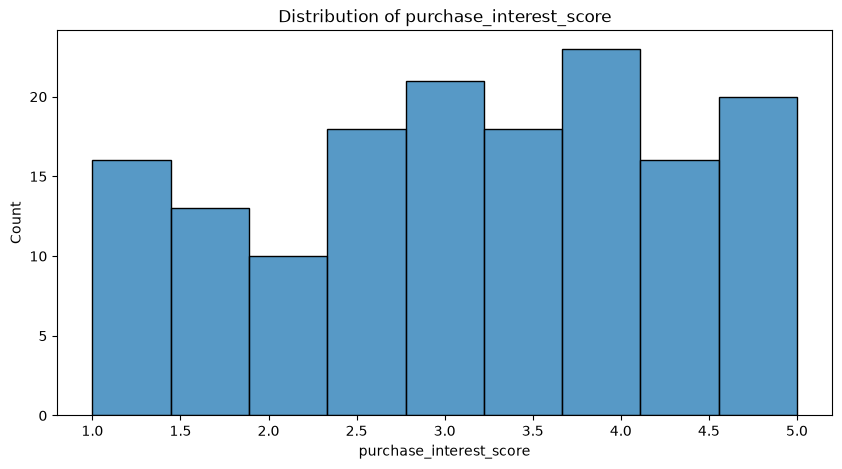

In [16]:
for i in Socials.select_dtypes(include="number").columns:
    plt.figure(figsize=(10,5))
    sns.histplot(Socials[i])
    plt.title("Distribution of " + i)
    plt.show()

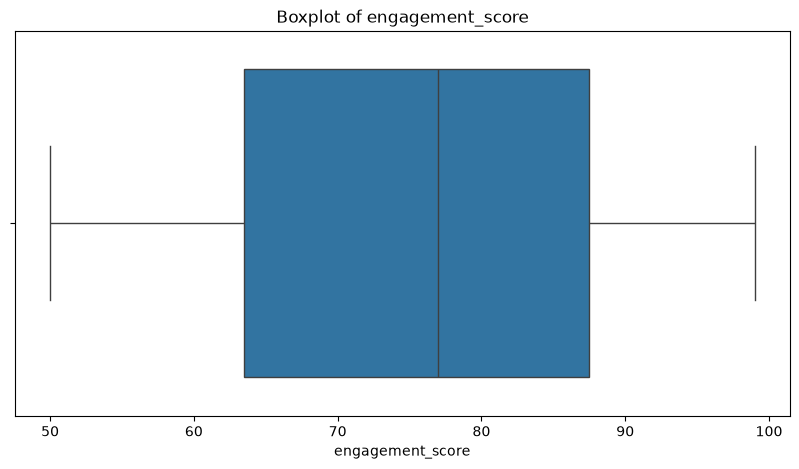

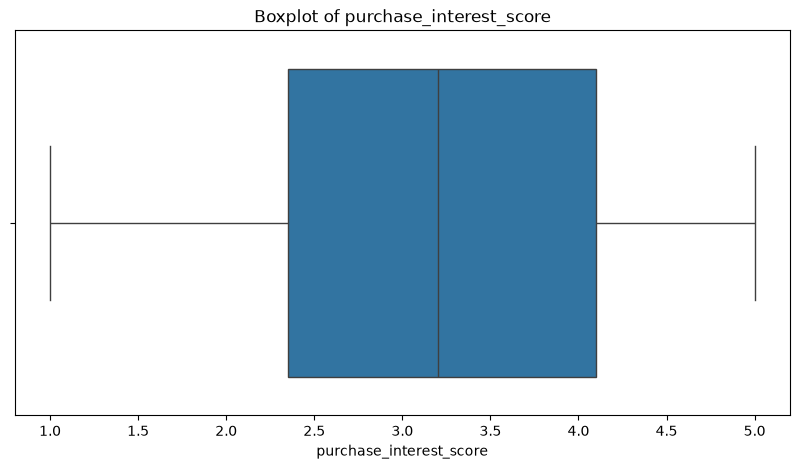

In [17]:
for i in Socials.select_dtypes(include="number").columns:
    plt.figure(figsize=(10,5))
    sns.boxplot(x=Socials[i])
    plt.title("Boxplot of " + i)
    plt.show()

**Explanation:** `value_counts()` shows how often each text value appears, `describe()` gives summary statistics, and histograms and boxplots show the shape of the numbers and any outliers. These are all good first looks at the data.

## Step 3: Clean each table separately

In [18]:
Socials =  Socials.drop_duplicates()
Socials = Socials.reset_index(drop=True)

print("Socials rows after removing duplicates:", Socials.shape[0])
print("Duplicates left:", Socials.duplicated().sum())

Socials rows after removing duplicates: 150
Duplicates left: 0


**Explanation:** Since the inspection found 5 duplicate rows in `Socials`, we remove them with `drop_duplicates()`. An exact duplicate adds no new information and can make one customer look more important than they are. We then print the new row count and the duplicates left, because we verify every cleaning step instead of assuming it worked (it should say 150 rows and 0 duplicates). `reset_index` simply renumbers the rows from 0.

In [19]:
Trans["purchase_date"] = pd.to_datetime(Trans["purchase_date"])

print(Trans.dtypes)

customer_id_legacy             int64
transaction_id                 int64
purchase_amount                int64
purchase_date         datetime64[us]
product_category                 str
customer_rating              float64
dtype: object


**Explanation:** `purchase_date` was stored as text, which pandas cannot do date maths on. `pd.to_datetime` converts it into a real date, so later we can pull out the month and the day of the week. Printing `dtypes` confirms it now says `datetime64`.

In [20]:
print("Missing ratings:", Trans["customer_rating"].isnull().sum())

Missing ratings: 10


## Step 4: Fix and check the join key


Here I first spilt the data into training and test sets.Then, I filled in the missing ratings using the median of the training set which was 3.5 and applied it to both sets.I did this to avoid using information from the test set.If I had used the median of entire dataset then I would mess with the test result.

**Explanation**: We do not fill the missing ratings yet because if we filled them with the median of the whole dataset now it would cause a leak into training from the future test rows. Here the important rule is to spilt first and then fill using the training data and this will be done in step 9

In [21]:
print("Socials IDs:", Socials["customer_id_new"].head(5).tolist())
print("Trans IDs:  ", Trans["customer_id_legacy"].head(5).tolist())

Socials IDs: ['A178', 'A190', 'A150', 'A162', 'A197']
Trans IDs:   [151, 192, 114, 171, 160]


**Explanation:** Before merging we compared how the Ids looks in each table. In Socials, Ids are written as text with a letter(A178) while in Trans it is written as number (151). Pandas can not match these different formats. if we merge them directly we may get zero matches without an error  so that's why we always check the Id formats before merging

In [22]:
Socials["customer_id"] = Socials['customer_id_new'].str.replace("A","").astype(int)
Trans["customer_id"] = Trans["customer_id_legacy"]

print("Socials customer_id range:", Socials["customer_id"].min(), "to", Socials["customer_id"].max())
print("Trans customer_id range:  ", Trans["customer_id"].min(), "to", Trans["customer_id"].max())

Socials customer_id range: 100 to 199
Trans customer_id range:   100 to 199


**Explanation:** Since the Ids are written differently in two tables we create a new column called customer_id in both tables and make sure the values have the same format(interger). We use .str.replace("A","") to remove the letter A and then .astype(int) to convert text into numbers. Then we come up with are range in which the ids in both tables will fall into (range from 100 t0 199)

In [23]:
social_ids = set(Socials["customer_id"])
trans_ids = set(Trans["customer_id"])

print("Unique customers in Socials:", len(social_ids))
print("Unique customers in Trans:", len(trans_ids))

in_both = social_ids & trans_ids
print("Customers in both tables:", len(in_both))


no_social = (~Trans["customer_id"].isin(social_ids)).sum()
print("Transactions with no social profile:", no_social)

Unique customers in Socials: 84
Unique customers in Trans: 75
Customers in both tables: 61
Transactions with no social profile: 33


**Explanation:** Before merging both we first check
how many customers appears in both tables and how many transactions belongs to the customers without social profile so that later if we use inner join and some transaction are lost/left out will know and understand our data more.


So according to the result Socials has 84 unique customers while Trans has 75 and only 61 of them appears in both tables. The remaining 14 customers in Trans table do not have social profiles. Together, these 14 customers accounts for 33 out of 150 tansactions (22%). When we use inner join, those 33 transactions are excludes leaving 117 rows in the merged table.

In [24]:
print("Rows per customer in Socials (top 5):")
print(Socials["customer_id"].value_counts().head())
print()
print("Rows per customer in Trans (top 5):")
print(Trans["customer_id"].value_counts().head())

Rows per customer in Socials (top 5):
customer_id
155    6
116    4
189    4
125    4
185    4
Name: count, dtype: int64

Rows per customer in Trans (top 5):
customer_id
161    6
187    5
159    5
114    4
101    4
Name: count, dtype: int64



**Explanation:** The grain of a table means what each row represents. In Trans table, each row represents one transactions so one customer can appear several times if they make multiple purchases.
However it is different in socials table because socials table should ideally have one row per customer profile.This shows that some customers appears in multiple rows possibly because they use different social media platforms.

So if we merge the tables directly customers with multiple social media profiles will cause duplicates into our data which can give us incorrect results.In the next cell will will correct this


## Step 5: Turn Socials into one row per customer

In [25]:
def most_common(values):
    return values.mode()[0]


Socials_one = Socials.groupby("customer_id").agg(
    engagement_score=("engagement_score", "mean"),
    purchase_interest_score=("purchase_interest_score", "mean"),
    num_profiles=("customer_id", "count"),
    main_platform=("social_media_platform", most_common),
    main_sentiment=("review_sentiment", most_common),
).reset_index()

print("Rows in Socials_one:", Socials_one.shape[0])
print("Is customer_id unique now?", Socials_one["customer_id"].is_unique)
Socials_one.head()

Rows in Socials_one: 84
Is customer_id unique now? True


,customer_id,engagement_score,purchase_interest_score,num_profiles,main_platform,main_sentiment
0,100,77.000000,4.400000,2,Instagram,Negative
1,101,68.000000,1.000000,1,Twitter,Neutral
2,102,51.000000,4.800000,1,LinkedIn,Neutral
3,103,64.333333,2.866667,3,Instagram,Positive
4,104,83.000000,2.933333,3,Twitter,Negative


**Explanation:** Here, we use *groupby("customer_id")* to combine multiple social records into one row per customer. we calculate the average for the number columns and keep the most common value for text columns. We also add *num_profiles* to show how many social records each customer had. Finally, we check that eac customer appears only once before merging.

In this cell, We summarised socials first to ensure each customer appears only once this prevents duplicate transactions when merging and helps us get accurate results for our model.

## Step 6: Merge and check

In [26]:
merged = pd.merge(
    Trans,
    Socials_one,
    on="customer_id",
    how="inner",
    validate="many_to_one",
)

print("Merge done")

Merge done


**Explanation:** We merge the two tables using customer_id. We use an inner join to keep only transactions whose customers also have social profiles.This ensures every row has both transaction and social data. We also use **Validate="many_to_one"** to prevent duplicate rows during merging.

We used an inner join because our model requires both transaction and social data for each customer, so we kept only customers who appeared in both tables.

In [27]:
print("Trans rows before merge:", len(Trans))
print("Customers in Socials_one:", len(Socials_one))
print("Merged rows after merge:", len(merged))
print("Rows lost:", len(Trans) - len(merged))
print("Is transaction_id unique?", merged["transaction_id"].is_unique)
print()
print("Nulls after merge:")
print(merged.isnull().sum())

Trans rows before merge: 150
Customers in Socials_one: 84
Merged rows after merge: 117
Rows lost: 33
Is transaction_id unique? True

Nulls after merge:
customer_id_legacy         0
transaction_id             0
purchase_amount            0
purchase_date              0
product_category           0
customer_rating            8
customer_id                0
engagement_score           0
purchase_interest_score    0
num_profiles               0
main_platform              0
main_sentiment             0
dtype: int64


**Explanation:** After merging, we check the results to make sure nothing went wrong. We compare the number of rows before and after merging, count the lost transactions, check that no transaction was duplicated and look for new missing values. The number of lost rows should match the transactions without social profiles and if they do not match it means something went wrong.

In [57]:
merged.to_csv("data/merged_dataset.csv", index=False)

print("Saved merged_dataset.csv")

Saved merged_dataset.csv


**Explanation:** **to_csv** writes the merged table to a file, and **index=False** stops pandas adding an extra numbering column. We are required to have **merged_dataset.csv** in GitHub repo. We will save an updated version again after feature engineering.

## Step 7: EDA on the merged table

In [29]:
print(merged.dtypes)
merged.describe().T

customer_id_legacy                  int64
transaction_id                      int64
purchase_amount                     int64
purchase_date              datetime64[us]
product_category                      str
customer_rating                   float64
customer_id                         int64
engagement_score                  float64
purchase_interest_score           float64
num_profiles                        int64
main_platform                         str
main_sentiment                        str
dtype: object


,count,mean,min,25%,50%,75%,max,std
customer_id_legacy,117.0,147.91453,100.0,117.0,146.0,180.0,199.0,32.288722
transaction_id,117.0,1074.25641,1001.0,1036.0,1073.0,1113.0,1150.0,44.27328
purchase_amount,117.0,287.905983,62.0,183.0,280.0,397.0,495.0,120.084165
purchase_date,117,2024-03-14 06:09:13.846153,2024-01-01 00:00:00,2024-02-05 00:00:00,2024-03-13 00:00:00,2024-04-22 00:00:00,2024-05-29 00:00:00,NaN
customer_rating,109.0,3.116514,1.0,2.1,3.3,4.2,5.0,1.23884
customer_id,117.0,147.91453,100.0,117.0,146.0,180.0,199.0,32.288722
engagement_score,117.0,74.154558,50.0,66.5,77.0,83.0,99.0,12.67478
purchase_interest_score,117.0,3.077208,1.0,2.666667,3.133333,3.7,4.8,1.039644
num_profiles,117.0,1.820513,1.0,1.0,2.0,2.0,4.0,0.896501


**Explanation:** Since the merged table is the only table the model will use, this is where the EDA that counts happens. **dtypes** lists the variable types and **describe()** gives the summary statistics.

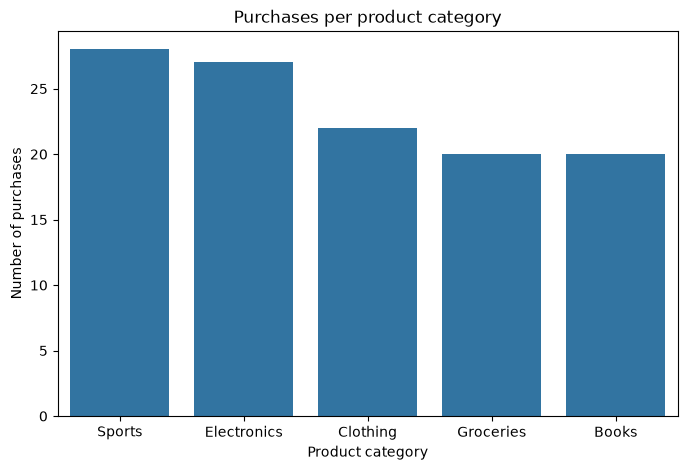

In [30]:
plt.figure(figsize=(8,5))
sns.countplot(data=merged, x="product_category")
plt.title("Purchases per product category")
plt.xlabel("Product category")
plt.ylabel("Number of purchases")
plt.show()

**Explanation:** A **count plot** counts each category. We look at the target first because it shows **class balance**. If one product dominated, a model that always guessed it would look accurate while learning nothing. Here the classes are fairly even, which is good, but notice the most common class also gives us our **baseline** later.

According to the plot, Sports has the most purchases followed by Electronics,Clothing,Groceries then Books. These categories are fairly balanced so  **Accuracy** is the suitable evaluation metric.

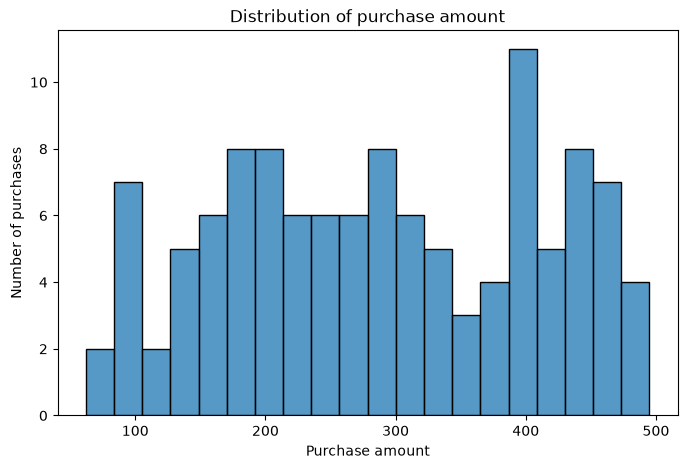

In [31]:
plt.figure(figsize=(8,5))
sns.histplot(merged["purchase_amount"], bins=20)
plt.title("Distribution of purchase amount")
plt.xlabel("Purchase amount")
plt.ylabel("Number of purchases")
plt.show()

**Explanation:** A **histogram** shows how values are spread: where most purchases fall, and whether the shape is lopsided. **bins=20** splits the range into 20 bars. We look at the distribution to understand what a typical purchase looks like.

Here, The purchase amounts range from about 60 to 500 with no clear pattern or strong skew.The highest bar is around 400 with 11 purchases. the median purchase amount is almost 280.


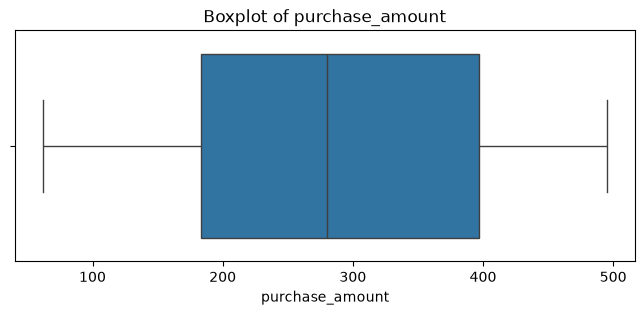

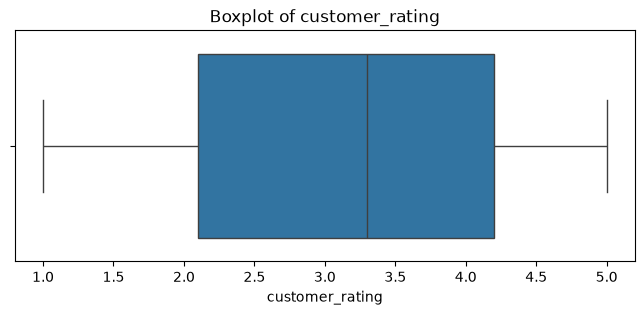

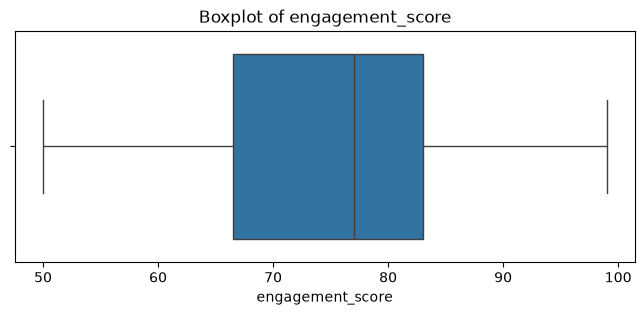

In [32]:
for col in ["purchase_amount", "customer_rating", "engagement_score"]:
    plt.figure(figsize=(8,3))
    sns.boxplot(x=merged[col])
    plt.title("Boxplot of " + col)
    plt.show()

**Explanation:** A **boxplot** shows the middle 50% of values as a box, and any dots outside the whiskers are **outliers**. We check for outliers because extreme values can distort some models. If there are none, that is a finding too.

There are no outliers in purchase_amount,customer_rating or engagement_score. All values fall with in the expected ranges so they are valid and I would not remove any rows because there are no outliers and the dataset is originally small.

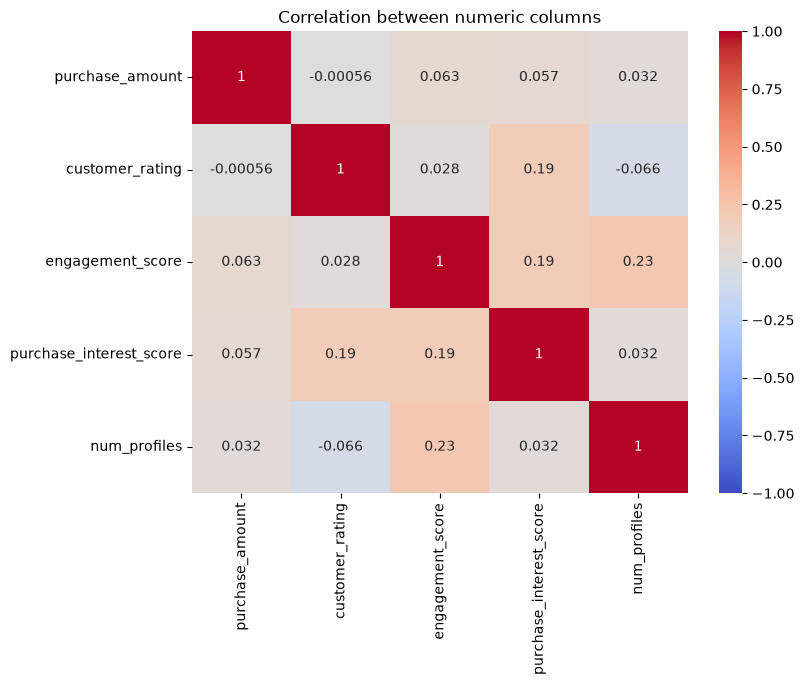

In [33]:
number_cols = ["purchase_amount", "customer_rating", "engagement_score",
               "purchase_interest_score", "num_profiles"]

corr = merged[number_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric columns")
plt.show()

**Explanation:** `.corr()` measures how strongly each pair of numeric columns moves together, from -1 (opposite) through 0 (unrelated) to +1 (together). The heatmap colors it so strong relationships stand out. We use it to spot features that say the same thing (which adds nothing) and to see whether any numeric feature relates to another.

Here, The correlations between all pairs of features are weak. the highest is about 0.23,meaning there is no stron relationship between the columns.This suggests that the features provide different information and multicollinearity is not a problem.

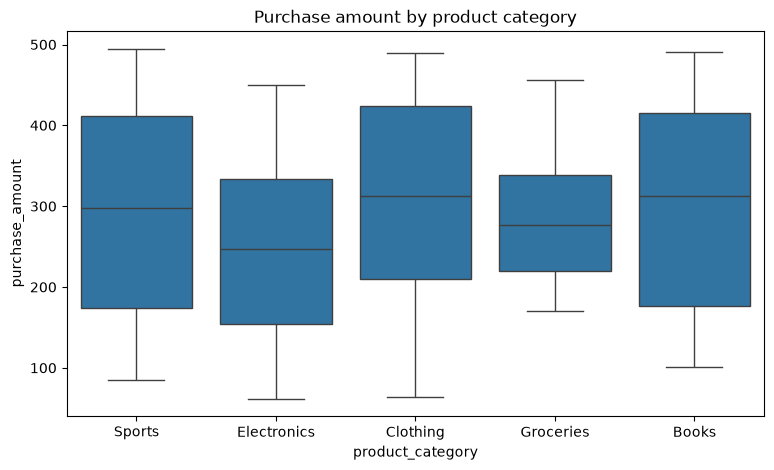

In [34]:
plt.figure(figsize=(9,5))
sns.boxplot(data=merged, x="product_category", y="purchase_amount")
plt.title("Purchase amount by product category")
plt.show()

**Explanation:** This compares a feature **against the target**. If the boxes sit at clearly different heights, the feature helps tell categories apart, and if they overlap heavily, it does not. This is the most useful kind of plot for deciding which features matter.

## Step 8: Feature engineering

In [35]:
merged["month"] = merged["purchase_date"].dt.month
merged["day_of_week"] = merged["purchase_date"].dt.dayofweek

merged[["purchase_date", "month", "day_of_week"]].head()

,purchase_date,month,day_of_week
0,2024-01-01,1,0
1,2024-01-02,1,1
2,2024-01-03,1,2
3,2024-01-05,1,4
4,2024-01-06,1,5


**Explanation:** A model cannot use a raw date, but it can use numbers derived from it. `.dt.month` gives the month (1 to 12) and `.dt.dayofweek` gives the weekday (0 = Monday). We created these only because we converted `purchase_date` to a real date in Step 3. They may or may not help, and the model will tell us.

**Explanation:** Before choosing features, we ask whether each column would be available when making a prediction. Social media information and purchase timing are safe to use. However, Purchase_amount and customer_rating are only known after the purchase,so we will them for this assignment and test the model without them in step 13. We exclude Ids and dates that only identify customers or transactions.We also exclude product_category because it is what we want the model to predict.

In [36]:
feature_cols = ["purchase_amount", "customer_rating",
                "engagement_score", "purchase_interest_score", "num_profiles",
                "month", "day_of_week",
                "main_platform", "main_sentiment"]

X = merged[feature_cols]
y = merged["product_category"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (117, 9)
y shape: (117,)


**Explanation:** `X` holds the inputs (the features) and `y` holds the answer (the target). We separate them so the model learns from `X` and is graded against `y`. The shapes should match in the number of rows. Notice that the ID columns, the date, and the target itself are **not** in `X`.

In [37]:
X = pd.get_dummies(X, columns=["main_platform", "main_sentiment"], dtype=int)

print("X shape after encoding:", X.shape)
X.head()

X shape after encoding: (117, 15)


,purchase_amount,customer_rating,engagement_score,purchase_interest_score,num_profiles,month,day_of_week,main_platform_Facebook,main_platform_Instagram,main_platform_LinkedIn,main_platform_TikTok,main_platform_Twitter,main_sentiment_Negative,main_sentiment_Neutral,main_sentiment_Positive
0,408,2.3,71.666667,2.166667,3,1,0,0,0,0,0,1,0,1,0
1,332,4.2,60.000000,4.300000,1,1,1,0,1,0,0,0,0,0,1
2,442,2.1,87.000000,4.800000,1,1,2,1,0,0,0,0,1,0,0
3,64,1.3,72.666667,2.500000,3,1,4,0,1,0,0,0,0,1,0
4,395,1.1,77.000000,2.666667,3,1,5,0,1,0,0,0,0,0,1


**Explanation:** Models only understand numbers, so `get_dummies` turns a text column like `main_platform` into one 0/1 column per value (`main_platform_Twitter`, `main_platform_TikTok`, ...). This is called **one-hot encoding**. We do not turn platforms into 1, 2, 3, because that would wrongly tell the model that TikTok is "bigger" than Twitter. The column count grows, and we will save this exact column list for the prediction function later.

In [58]:
merged.to_csv("data/merged_dataset.csv", index=False)

## Step 9: Split first, then fill and scale

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)

X_train: (93, 15)
X_test:  (24, 15)


**Explanation:** We hide 20% of the rows (`test_size=0.2`) that the model never sees during training, so the test score honestly shows how it behaves on new customers. `stratify=y` keeps each product's share the same in train and test, which matters with so few rows. `random_state=42` makes the split repeatable. From this point on, **anything we learn from data (a median, a scaler) comes from `X_train` only**.

In [40]:
median_rating = X_train["customer_rating"].median()

X_train = X_train.fillna({"customer_rating": median_rating})
X_test = X_test.fillna({"customer_rating": median_rating})

print("Median rating (from train):", median_rating)
print("Missing in train:", X_train["customer_rating"].isnull().sum())
print("Missing in test:", X_test["customer_rating"].isnull().sum())

Median rating (from train): 3.5
Missing in train: 0
Missing in test: 0


In [61]:
model_ready = pd.concat([X_train, X_test]).sort_index()
model_ready["product_category"] = y
model_ready.to_csv("data/model_ready_dataset.csv", index=False)

**Explanation:** Now we handle the 10 missing ratings. We compute the median from the **training** rows only and use that same number for both sets, so nothing about the test rows influences training. We use the median instead of the mean because it is not pulled around by extreme values. Both counts should print 0.

In [42]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train mean after scaling:", round(float(X_train_scaled.mean()), 3))

Train mean after scaling: -0.0


**Explanation:** Columns have very different sizes (`purchase_amount` goes up to about 500, ratings only to 5), and Logistic Regression trains badly when scales differ. `StandardScaler` rescales each column to roughly mean 0 and spread 1. Notice the difference between `fit_transform` on training (it **learns** the scaling and applies it) and `transform` on test (it only **applies** what it learned). Using `fit` on the test set would be leakage. The Random Forest does not need scaling, so it uses the unscaled data.

## Step 10: Baseline (the score to beat)

In [43]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="prior")
baseline.fit(X_train, y_train)

print("Baseline always predicts:", baseline.classes_[baseline.class_prior_.argmax()])

Baseline always predicts: Sports


**Explanation:** Before building real models we set a **baseline**: a "model" that ignores every feature and always guesses the most common product (`strategy="prior"` also gives probabilities equal to each product's overall share, so log loss stays meaningful). Any real model must clearly beat it to be worth using. With five fairly even classes, expect the baseline to score only around 20 to 25%. It gives us the honest starting line for judging our results.

## Step 11: Train the models

In [44]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

print("Both models trained")

Both models trained


**Explanation:** `fit(X_train, y_train)` is where learning happens: the model studies the training rows and their correct products. **Logistic Regression** is our simple, easy-to-explain model (despite its name, it is a classifier). It gets the scaled data. **Random Forest** builds many decision trees and lets them vote, so it can find more complex patterns, and it does not need scaling. `random_state=42` makes the results repeatable, and `max_iter=1000` gives Logistic Regression enough steps to finish learning.

## Step 12: Evaluate on the test set

In [45]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, log_loss


def evaluate_model(name, model, X_test_data, y_test):
    y_pred = model.predict(X_test_data)
    y_prob = model.predict_proba(X_test_data)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="weighted")
    loss = log_loss(y_test, y_prob, labels=model.classes_)

    print(name)
    print("  Accuracy:", round(acc, 4))
    print("  F1 (weighted):", round(f1, 4))
    print("  Log loss:", round(loss, 4))

    return {"Model": name, "Accuracy": acc, "F1 (weighted)": f1, "Log loss": loss}

**Explanation:** We wrap the three required metrics in one helper so every model is judged the same way. `predict` gives the chosen product, while `predict_proba` gives a probability for each product, which **log loss** needs. **Accuracy** is the share of correct guesses. **F1** balances precision and recall across classes (`weighted` averages them by class size). **Log loss** punishes confident wrong answers, and **lower is better**. We are asked for exactly these three for each model.

In [46]:
baseline_results = evaluate_model("Baseline", baseline, X_test, y_test)
print("-"*40)
lr_results = evaluate_model("Logistic Regression", log_reg, X_test_scaled, y_test)
print("-"*40)
rf_results = evaluate_model("Random Forest", rf, X_test, y_test)
print("-"*40)

results = pd.DataFrame([baseline_results, lr_results, rf_results])
results

Baseline
  Accuracy: 0.25
  F1 (weighted): 0.1
  Log loss: 1.5928
----------------------------------------
Logistic Regression
  Accuracy: 0.1667
  F1 (weighted): 0.1603
  Log loss: 2.4279
----------------------------------------
Random Forest
  Accuracy: 0.1667
  F1 (weighted): 0.1611
  Log loss: 1.6691
----------------------------------------


,Model,Accuracy,F1 (weighted),Log loss
0,Baseline,0.250000,0.100000,1.592783
1,Logistic Regression,0.166667,0.160256,2.427867
2,Random Forest,0.166667,0.161111,1.669121


**Explanation:** We run the helper on each model and collect the results in one table so they can be compared side by side. Note that Logistic Regression is tested on the **scaled** test data and the others on the normal test data, matching how each was trained.

Random forest performed slightly better then logistic regression and baseline in cross-validation. However, the improvement was small and overall results were weak suggesting that the features the provide limited information for predicting product categories.

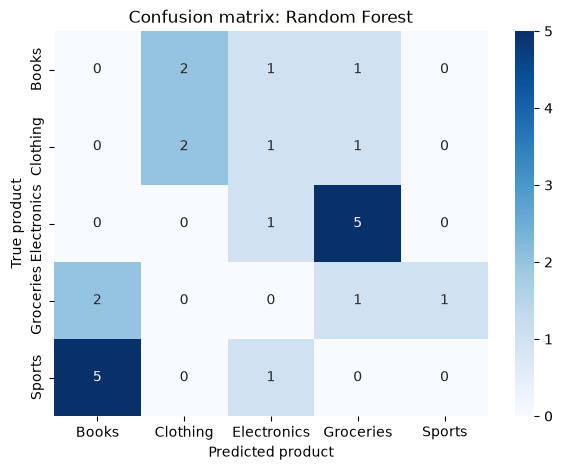

In [47]:
y_pred_rf = rf.predict(X_test)

cm = confusion_matrix(y_test, y_pred_rf, labels=rf.classes_)

plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=rf.classes_, yticklabels=rf.classes_)
plt.xlabel("Predicted product")
plt.ylabel("True product")
plt.title("Confusion matrix: Random Forest")
plt.show()

**Explanation:** The confusion matrix shows, for each **true** product (rows), what the model **predicted** (columns). The diagonal is correct answers, and anything off the diagonal is a mix-up. It reveals what accuracy hides: for example, whether the model handles one category well and ignores another. Change `rf` to `log_reg` (and use the scaled data) to compare.

In [48]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    "Baseline": make_pipeline(SimpleImputer(strategy="median"), DummyClassifier(strategy="prior")),
    "Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=200, random_state=42)),
}

rows = []
for name, m in cv_models.items():
    acc = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    f1 = cross_val_score(m, X, y, cv=cv, scoring="f1_weighted")
    ll = -cross_val_score(m, X, y, cv=cv, scoring="neg_log_loss")
    rows.append({"Model": name, "Accuracy": acc.mean(), "Accuracy std": acc.std(),
                 "F1 (weighted)": f1.mean(), "Log loss": ll.mean()})

pd.DataFrame(rows).round(3)

,Model,Accuracy,Accuracy std,F1 (weighted),Log loss
0,Baseline,0.214,0.004,0.075,1.600
1,Logistic Regression,0.240,0.026,0.223,1.939
2,Random Forest,0.290,0.061,0.275,1.593


## Step 13: Experiments

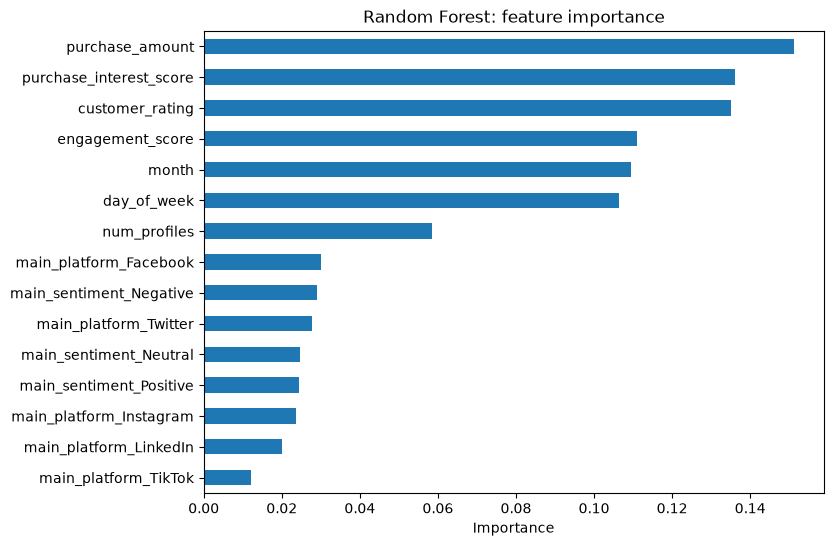

In [49]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
importances = importances.sort_values()

plt.figure(figsize=(8,6))
importances.plot(kind="barh")
plt.title("Random Forest: feature importance")
plt.xlabel("Importance")
plt.show()

**Explanation:** Feature importance shows which columns the forest used most to decide. This is a quick leakage detector: if one column dominates suspiciously, ask why. It also tells you which features earn their place.

Purchase_amount is the most important feature(0.15), followed by purchase_interest_score and customer_rating(about 0.135 each). Engagement and data feature have moderate importance while platform sentiment have the least. No single feature dominates.However, month and day of the week may be capturing random patterns rather than meaningful information.Also,purchase_amount and customer_rating are only known after a purchase which is a limit


In [50]:
drop_cols = ["purchase_amount", "customer_rating"]

X_train_small = X_train.drop(columns=drop_cols)
X_test_small = X_test.drop(columns=drop_cols)

rf_small = RandomForestClassifier(n_estimators=200, random_state=42)
rf_small.fit(X_train_small, y_train)

small_results = evaluate_model("Random Forest (without amount and rating)", rf_small, X_test_small, y_test)

Random Forest (without amount and rating)
  Accuracy: 0.1667
  F1 (weighted): 0.1702
  Log loss: 3.128


**Explanation:** `purchase_amount` and `customer_rating` describe the purchase itself, so strictly they would not be known before a customer decides what to buy. Here we retrain without them and compare. If the score barely changes, those columns were not doing much. If it drops a lot, the model was leaning on information from the purchase itself.

Dropping purchase_amount and customer_rating left accuracy unchanged (0.1667 both times) and moved F1 only a little (0.170 against 0.161), but log loss rose from 1.669 to 3.128. So on this split the two columns were not needed to pick a class, though they helped the probabilities. With only 24 test rows, the accuracy and F1 differences are within noise. These two columns describe the purchase itself, so a real system would not have them before a customer chooses a product. It could only use the other features, and its probabilities would be less reliable.



## Step 14: Save the model and the prediction function

In [62]:
import joblib

best_model = rf
use_scaler = False

joblib.dump(best_model, "models/product_model.pkl")
joblib.dump(list(X_train.columns), "models/feature_columns.pkl")
joblib.dump(median_rating, "models/median_rating.pkl")
joblib.dump(scaler, "models/scaler.pkl")

print("Saved: models/product_model.pkl, models/feature_columns.pkl, models/median_rating.pkl, models/scaler.pkl")

Saved: models/product_model.pkl, models/feature_columns.pkl, models/median_rating.pkl, models/scaler.pkl


**Explanation:** Training happens once, but the model must be used later while doing command-line app. `joblib.dump` saves Python objects to files. We save four things, not just the model, because at prediction time the new customer's data must go through the **same preparation**: the same columns in the same order, the same median for a missing rating, and the same scaler if Logistic Regression was chosen. Forgetting these is the most common reason a deployed model gives wrong answers.

In [52]:
def predict_product(customer):
  customer = dict(customer)
  rating = customer.get("customer_rating")
  if rating is None or pd.isna(rating):
    customer["customer_rating"] = median_rating
  row = pd.DataFrame([customer])
  row = pd.get_dummies(row)
  row = row.reindex(columns=list(X_train.columns), fill_value=0)
  row = row.fillna({"customer_rating": median_rating})

  if use_scaler:
    row = scaler.transform(row)
  prediction = best_model.predict(row)[0]
  return prediction

**Explanation:** This function repeats the exact preparation steps for a single new customer and returns the predicted product name. `get_dummies` on one row creates only the columns it sees (for example only `main_platform_Twitter`), so `reindex(columns=..., fill_value=0)` adds all the missing columns as 0 and puts them in the training order. Without that line, the model would crash or silently read the wrong columns.

In [53]:
test_customer = {
    "purchase_amount": 250,
    "customer_rating": 3.5,
    "engagement_score": 80,
    "purchase_interest_score": 4.0,
    "num_profiles": 1,
    "month": 3,
    "day_of_week": 2,
    "main_platform": "Twitter",
    "main_sentiment": "Positive",
}

print("Predicted product:", predict_product(test_customer))
test_customer["customer_rating"] = None
print("Predicted product (rating missing):", predict_product(test_customer))

Predicted product: Books
Predicted product (rating missing): Books


**Explanation:** We always test the function before handing it over. The second call leaves the rating empty to check that the median fill works. When my fellow uses files, He load the four `.pkl` files with `joblib.load` and call `predict_product` with a dictionary shaped like `test_customer`.

In [60]:
for f in ["data/merged_dataset.csv", "data/model_ready_dataset.csv"]:
  d = pd.read_csv(f)
  print(f, d.shape, "nulls:", int(d.isnull().sum().sum()))

data/merged_dataset.csv (117, 14) nulls: 8
data/model_ready_dataset.csv (117, 16) nulls: 0


**Summary:**


*   Merged dataset ended up with 117 rows which resulted with 33 transactions dropped from original 150 transactions because some of the customer with no social profile.
*   Best Model is Random forest where in 5-fold cross-validation scored the accuracy of 0.290 weighted F1 0.275 and log loss 0f 1.593 against baseline 0.214,0.075 F1 and 1.600. The difference is very small meaning that features in our small dataset carry weak signal(so we need a big/enough dataset to have a reliable/confident results)

*   Files: Merged_dataset.csv,model_ready_dataset.csv,product_model.pkl,feature_columns.pkl,meadian_rating.pkl,scaler.pkl, product_model.py.



